# qregime tutorial: QEM, QEC or FTQC?

Before running a quantum circuit you have to decide how to deal with errors:

* **QEM** (error *mitigation*): run it on the raw physical qubits and correct the statistics afterwards. Cheap in qubits, but it only works while the circuit is short enough that noise hasn't drowned the signal.
* **QEC / FTQC** (error *correction* / full fault tolerance): encode every logical qubit into many physical ones. Arbitrarily reliable, but the overhead is often thousands of physical qubits per circuit.
* **Partial QEC**: a small code that doesn't reach full fault tolerance but buys real reliability at a fraction of the cost.

`qregime` makes that decision explicit and reproducible from a single OpenQASM file. This tutorial walks through each step on real circuits, including the cases where the tool says **"no regime works yet"** and why that is a useful answer.

Runtime: about 2 minutes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import qregime
print("qregime", qregime.__version__)

CIRCUITS = "../examples/circuits"
path = lambda name: f"{CIRCUITS}/{name}.qasm"

qregime 0.1.0


## 1. Hardware profiles

The only place hardware enters the tool is a small profile: the two-qubit error rate, the connectivity, and the circuit-level noise model the surface-code threshold was fitted for (`si1000` for superconducting qubits, `toy` with cheap idles for trapped ions; fitted with Deltakit, see `research/qec/fit_threshold_deltakit.py`). Everything else (profiling, recommendations) is hardware-agnostic by construction. Three published profiles ship with the package; you can define your own with `qregime.HardwareProfile`.

In [2]:
for key, hw in qregime.HARDWARE_PROFILES.items():
    print(f"{key:28s} p_2q = {hw.p_2q:<7g} noise = {hw.noise_model:7s} {hw.connectivity}")

superconductor_ibm           p_2q = 0.0032  noise = si1000  limited
trapped_ion_quantinuum_h2    p_2q = 0.001   noise = toy     all_to_all
trapped_ion_ionq_oxford      p_2q = 0.0001  noise = toy     all_to_all


## 2. Profile a circuit

`profile()` reads the QASM and computes structural features: size, T-count (the expensive non-Clifford gates in fault-tolerant computing), how the qubits interact, how many qubits are really alive at the same time (a mid-circuit-measurement reuse opportunity), and how entangled the final state is.

In [3]:
p = qregime.profile(path("shor_like_sequential"))
for k in ("num_qubits", "num_gates", "tcount", "two_qubit_count",
          "max_concurrent_qubits", "qubit_reuse_potential_fraction",
          "zz_cost_operator_motif_fraction", "final_state_entanglement_fraction"):
    print(f"{k:34s} {p[k]}")

num_qubits                         16
num_gates                          28618
tcount                             3930
two_qubit_count                    3108
max_concurrent_qubits              11
qubit_reuse_potential_fraction     0.3125
zz_cost_operator_motif_fraction    0.0
final_state_entanglement_fraction  0.29167025434636823


Two things to notice: the circuit declares 16 qubits but only 11 are ever alive at the same time (31% reuse potential), and its T-count of 3,930 is what makes fault tolerance expensive for it.

## 3. Which reduction techniques are worth trying?

Reducing a circuit *before* choosing a regime can flip the decision. `recommend()` says which techniques are worth trying and why.

The most interesting case is ZX-calculus T-count reduction. The paper proves (Proposition 1) that when all the non-Clifford content of a circuit is a single layer of diagonal $Z_aZ_b$ rotations on distinct qubit pairs (the structure of a QAOA cost layer, or an Ising Trotter step), ZX-calculus **cannot** reduce the T-count at all. The feature `zz_cost_operator_motif_fraction` detects that structure. Let's check the prediction against the real reduction:

In [4]:
import pyzx as zx
from qregime.zx_reduction import zx_reduce
from qregime.hypergraph import resource_report

print(f"{'circuit':26s} {'motif':>6s} {'T before':>9s} {'T after':>8s} {'reduction':>10s}")
for name in ["adder8", "qft10", "qaoa_farm", "kicked_ising_analog_16q"]:
    circ = zx.Circuit.from_qasm_file(path(name)).to_basic_gates()
    before = resource_report(circ)["tcount"]
    after = resource_report(zx_reduce(circ))["tcount"]
    motif = qregime.profile(path(name))["zz_cost_operator_motif_fraction"]
    print(f"{name:26s} {motif:6.2f} {before:9d} {after:8d} {(before - after) / before:10.0%}")

circuit                     motif  T before  T after  reduction


adder8                       0.00       112       64        43%


qft10                        0.00       135       63        53%
qaoa_farm                    1.00        56       56         0%


kicked_ising_analog_16q      1.00       124      124         0%


Circuits with the diagonal-layer motif (`motif = 1.0`) get exactly 0% reduction, as the proposition says; the others get 43-53%. The tool uses this to warn you *before* you spend compile time:

In [5]:
for name in ["adder8", "qaoa_farm"]:
    recs = qregime.recommend(path(name))
    zxr = recs["zx_calculus_tcount_reduction"]
    print(f"{name:10s} -> recommended: {zxr['recommended']}")

adder8     -> recommended: True
qaoa_farm  -> recommended: WARNING


*(The `reason` strings are currently in Spanish, the language the research was done in. Translating them is an open, welcome contribution.)*

## 4. What would full fault tolerance cost?

`estimate_ftqc()` picks the surface-code distance from this project's own threshold fit for the hardware's noise model (measured with Deltakit + PyMatching, not a number from a paper) and adds Litinski's 15-to-1 magic-state factories. The same circuit on three kinds of hardware:

In [6]:
p = qregime.profile(path("shor_like_sequential"))
for key, hw in qregime.HARDWARE_PROFILES.items():
    for label, n in (("declared qubits", p["num_qubits"]), ("with reuse", p["max_concurrent_qubits"])):
        r = qregime.estimate_ftqc(n, p["tcount"], hw.p_2q, noise_model=hw.noise_model)
        if not r["feasible"]:
            print(f"{key:28s} {label:16s} not feasible: {r['reason']}")
            continue
        print(f"{key:28s} {label:16s} d={r['codeDistance']:2d}  {r['physicalQubits']:>7,} physical qubits")

superconductor_ibm           declared qubits  not feasible: no code distance up to d=51 meets the logical error budget (p_2q is too close to the fitted threshold)
superconductor_ibm           with reuse       not feasible: no code distance up to d=51 meets the logical error budget (p_2q is too close to the fitted threshold)
trapped_ion_quantinuum_h2    declared qubits  d=11    6,534 physical qubits
trapped_ion_quantinuum_h2    with reuse       d=11    5,324 physical qubits
trapped_ion_ionq_oxford      declared qubits  d= 5    1,350 physical qubits
trapped_ion_ionq_oxford      with reuse       d= 5    1,100 physical qubits


On the superconducting profile, 0.32% is too close to the SI1000 threshold (0.40%): no code distance up to 51 meets the error budget, so full fault tolerance is not an option at any size. On trapped ions, better hardware shrinks the code distance and qubit reuse shrinks the number of logical patches; both matter by thousands of physical qubits, which is why the tool reports both.

How good would the superconducting device have to be? Sweeping the error rate answers it: partial QEC starts to work below ~0.29%, full fault tolerance below ~0.25%, and it only gets affordable around 0.1%.

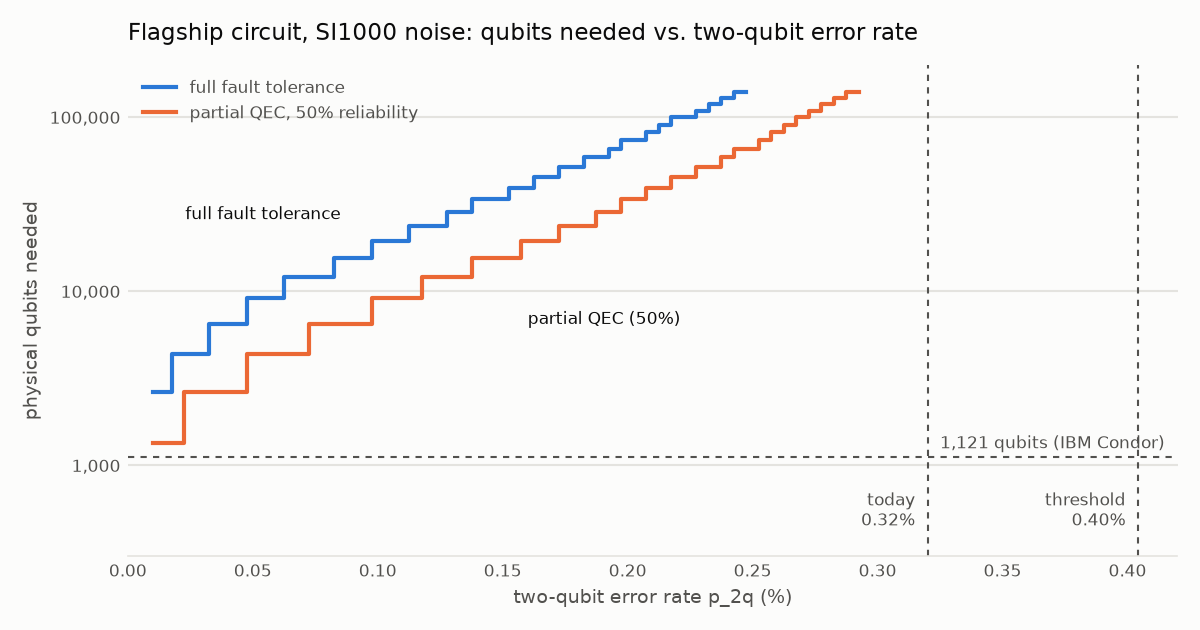

In [7]:
import sys
sys.path.insert(0, "../examples")
from error_rate_sweep import plot as plot_sweep
from IPython.display import Image

Image(plot_sweep("error_rate_sweep.png"), width=720)

## 5. The budget question: what can I get with the qubits I actually have?

On the trapped-ion H2 profile (0.1%), full fault tolerance for this circuit needs 6,534 physical qubits; the largest single device reported so far has 1,121. Instead of answering "not feasible", `best_within_budget()` returns the best reliability reachable at a fixed budget and its confidence quartile. The paper proves (Proposition 3) that this can only improve as the budget grows, so the curve below is guaranteed to be a staircase that never steps down.

In [8]:
for budget in (1_121, 2_000, 3_000, 5_000, 7_000):
    r = qregime.best_within_budget(16, 3930, 0.001, budget, noise_model="toy")
    print(f"budget {budget:>6,}: d={r['code_distance']:2d}  reliability {r['reliability']:6.1%}  "
          f"(quartile {r['confidence_quartile']}, {r['confidence_label']})")

budget  1,121: d= 3  reliability   0.0%  (quartile 1, low)
budget  2,000: d= 5  reliability   1.3%  (quartile 1, low)
budget  3,000: d= 7  reliability  59.7%  (quartile 3, moderate)
budget  5,000: d= 9  reliability  94.1%  (quartile 4, high)
budget  7,000: d=11  reliability  99.3%  (quartile 4, high)


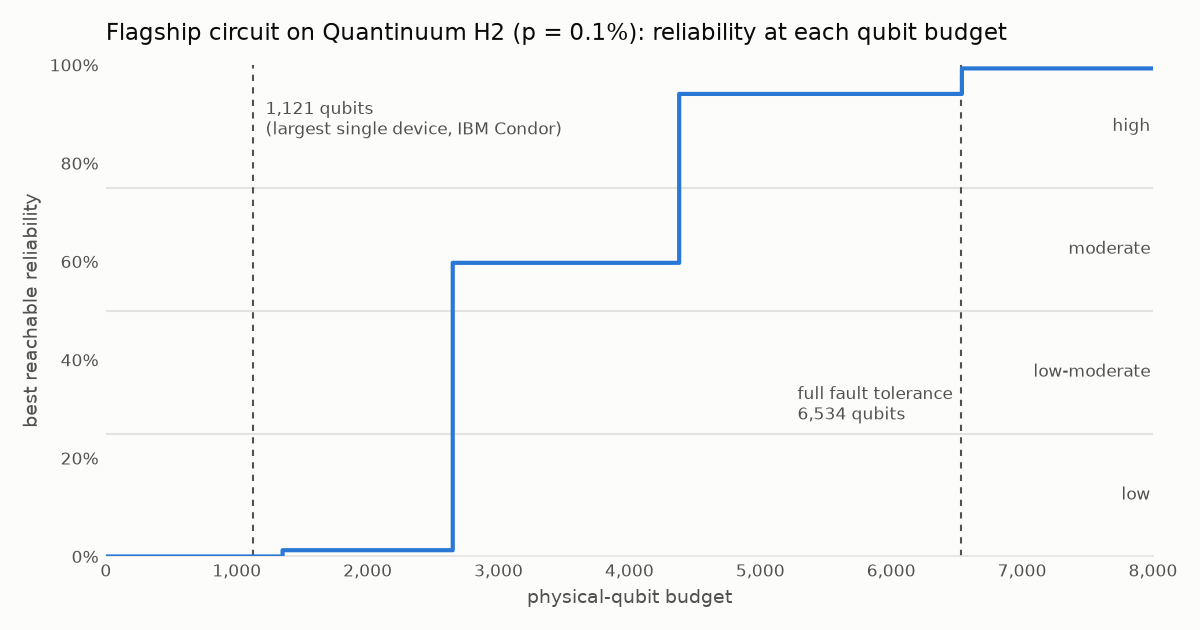

In [9]:
from budget_staircase import plot

Image(plot("budget_staircase.png"), width=720)

Reading the chart: at today's largest device (dashed line on the left) no code distance helps this circuit yet; reliability leaves the lowest quartile at ~2,650 qubits, where partial QEC (d=7) already gives 60% reliability at 40% of the cost of full fault tolerance. That is the kind of number a hardware roadmap needs.

## 6. The decision

`decide_regime()` puts it all together: the cheapest regime whose reliability meets your target within your budget, or an explicit, quantified gap if none does.

In [10]:
for name in ["vqe_ansatz", "adder8", "shor_like_sequential"]:
    r = qregime.decide_regime(path(name), hardware="superconductor_ibm",
                              physical_qubit_budget=1_121, reliability_target=0.5)
    ftqc = r["ftqc"]["cost_qubits"]
    print(f"{name:22s} regime={r['regime']:5s}  QEM reliability={r['qem']['reliability']:.1%}  "
          f"FTQC qubits={'not feasible' if ftqc is None else f'{ftqc:,}'}")
    if r["gap"]:
        g = r["gap"]
        over = g["ftqc_qubit_overrun"]
        print(f"{'':22s} gap: QEM short by {g['qem_reliability_shortfall']:.0%}, "
              + ("FTQC not feasible" if over is None else f"FTQC over budget by {over:,} qubits"))

vqe_ansatz             regime=QEM    QEM reliability=95.6%  FTQC qubits=not feasible


adder8                 regime=QEM    QEM reliability=75.3%  FTQC qubits=not feasible


shor_like_sequential   regime=GAP    QEM reliability=0.0%  FTQC qubits=not feasible
                       gap: QEM short by 50%, FTQC not feasible


Changing the hardware changes the answer without touching the circuit. On a device with 99.99% two-qubit fidelity, the same circuit that had no viable regime above now runs acceptably *without any error correction*: better hardware doesn't only make fault tolerance cheaper, it can make it unnecessary for a given circuit.

In [11]:
for hw in qregime.HARDWARE_PROFILES:
    r = qregime.decide_regime(path("shor_like_sequential"), hardware=hw)
    ftqc = r["ftqc"]["cost_qubits"]
    print(f"{hw:28s} regime={r['regime']:5s}  QEM reliability={r['qem']['reliability']:5.1%}  "
          f"FTQC qubits={'not feasible' if ftqc is None else f'{ftqc:>6,}'}")

superconductor_ibm           regime=GAP    QEM reliability= 0.0%  FTQC qubits=not feasible


trapped_ion_quantinuum_h2    regime=GAP    QEM reliability=10.0%  FTQC qubits= 6,534


trapped_ion_ionq_oxford      regime=QEM    QEM reliability=83.3%  FTQC qubits= 1,350


## 7. Where the QEM reliability number comes from (and when not to trust it)

For small circuits the QEM reliability comes from a noisy simulation: the fraction of shots that land on outputs the ideal circuit can produce. That metric is **useless** when the ideal circuit can produce almost every output (QAOA, VQE, QFT on superposed inputs): every noisy shot "succeeds". `qregime` detects this and falls back to an analytic proxy, and tells you so:

In [12]:
for name in ["adder8", "vqe_ansatz"]:
    r = qregime.decide_regime(path(name))
    print(f"{name:12s} {r['qem']['reliability']:.1%}  <- {r['qem']['reliability_source']}")

adder8       75.3%  <- noisy_simulation (150 shots)
vqe_ansatz   95.6%  <- analytic_proxy (1-p_2q)^two_qubit_count; noisy simulation not used: ideal output support covers 100% of all bitstrings, so it cannot detect errors


If you have a better number (measured on hardware, or from your own mitigation stack), pass it in with `qem_success_fraction=` and the decision uses it.

## 8. Honest limitations

These are stated in the paper and in the code, not hidden:

* **Thresholds depend on the noise model.** Each profile uses a fit for one circuit-level noise model (SI1000 or ToyNoise), validated within a factor 1.34 on held-out points up to d = 13 (`examples/deltakit_crosscheck.py`), but not an architecture-specific error model (leakage, crosstalk, correlated errors). d = 3 is outside the fit (d >= 5) and is an extrapolation.
* **No predictor of "will ZX-calculus help?" beats the majority baseline on unseen circuit families** (three attempts, including logistic regression and decision trees under leave-one-family-out validation). Proposition 1 gives an exact answer only for the diagonal-layer case.
* **Dynamic circuits** (mid-circuit measurement with classically controlled corrections) cannot be ingested yet: neither this tool nor the ZX-calculus state of the art we tested can represent arbitrary-angle classically-controlled corrections.
* **The QEM noise model** is generic two-qubit depolarizing noise; no readout, T1/T2 or crosstalk.
* **Speed:** pyzx's QASM parser becomes the bottleneck for circuits with many distinct rotation angles (a 24-qubit QFT did not finish in minutes).

Contributions on any of these are very welcome; see `CONTRIBUTING.md`.